<a href="https://colab.research.google.com/github/suhailabdulwasi/walmart-hurricane-project/blob/main/notebooks/walmart_hurricane_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Walmart Hurricane Analytics
**DS 2002 — Midterm Project**
**Author: Suhail Abdulwasi**

This notebook loads and analyzes Walmart transaction, product,
store, distribution-center, and SQLite data with historical weather
from Open-Meteo. It investigates demand surges, SKU fragmentation,
weather relationships, store differences, and the reliability of
the reported board-game sales increase.

### Q1 — Demand surge

In [1]:
import pandas as pd

BASE = (
    "https://raw.githubusercontent.com/jasontpv/DS2002FA26/"
    "main/notebooks/06-midterm-walmart/data/"
)

sales_raw = pd.read_csv(BASE + "walmart_transactions.csv")
catalog = pd.read_csv(BASE + "product_catalog.csv")
stores = pd.read_csv(BASE + "store_locations.csv")
distribution_centers = pd.read_csv(BASE + "distribution_centers.csv")

print("Distribution centers:", len(distribution_centers))
display(distribution_centers)

sales_clean = sales_raw.drop_duplicates().copy()

sales_clean["timestamp"] = pd.to_datetime(
    sales_clean["timestamp"], format="mixed", errors="coerce"
)

sales_clean["quantity"] = pd.to_numeric(
    sales_clean["quantity"], errors="coerce"
)

sales_clean["unit_price"] = pd.to_numeric(
    sales_clean["unit_price"].astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip(),
    errors="coerce"
)

sales_clean["store_id"] = (
    sales_clean["store_id"].astype("string").str.strip().str.upper()
)

print("Rows loaded:", len(sales_raw))
print("Rows after removing exact duplicates:", len(sales_clean))

Distribution centers: 5


,dc_id,dc_name,city,state,avg_daily_shipments,surge_capacity,distance_to_orlando_mi,cost_per_shipment
0,DC-JAX,Jacksonville Distribution Center,Jacksonville,FL,500,1000,141,245.0
1,DC-ATL,Atlanta Distribution Center,Atlanta,GA,400,700,438,412.5
2,DC-DAL,Dallas Distribution Center,Dallas,TX,300,600,1108,687.0
3,DC-MIA,Miami Distribution Center,Miami,FL,350,~750,235,298.0
4,DC-BHM,Birmingham Distribution Center,Birmingham,AL,250,500,503,NaN


Rows loaded: 25562
Rows after removing exact duplicates: 25532


In [2]:
category_map = {
    "alcohol": "Alcoholic Beverages",
    "alcoholic beverages": "Alcoholic Beverages",
    "baby": "Baby Products",
    "baby products": "Baby Products",
    "breakfast": "Breakfast Foods",
    "breakfast foods": "Breakfast Foods",
    "electronics": "Electronics",
    "emergency": "Emergency Supplies",
    "emergency supplies": "Emergency Supplies",
    "entertainment": "Games & Entertainment",
    "games & entertainment": "Games & Entertainment",
    "groceries": "Grocery",
    "grocery": "Grocery",
    "health": "Health & Wellness",
    "health & wellness": "Health & Wellness",
    "household": "Household Essentials",
    "household essentials": "Household Essentials",
    "snacks": "Snacks"
}

analysis_sales = sales_clean.copy()

analysis_sales["category_clean"] = (
    analysis_sales["category"]
    .astype("string").str.strip().str.lower()
    .map(category_map)
)

# Exclude rows that cannot support daily unit comparisons.
valid = (
    analysis_sales["timestamp"].notna()
    & analysis_sales["category_clean"].notna()
    & analysis_sales["quantity"].notna()
    & analysis_sales["quantity"].ge(0)
)

print("Rows excluded from analysis:", int((~valid).sum()))
analysis_sales = analysis_sales.loc[valid].copy()
analysis_sales["date"] = analysis_sales["timestamp"].dt.normalize()

baseline_start = pd.Timestamp("2024-09-05")
baseline_end = pd.Timestamp("2024-09-18")
surge_start = pd.Timestamp("2024-09-19")
surge_end = pd.Timestamp("2024-09-25")
landfall = pd.Timestamp("2024-09-26")

daily_units = (
    analysis_sales.groupby(["date", "category_clean"])["quantity"]
    .sum()
    .unstack(fill_value=0)
    .reindex(pd.date_range("2024-09-01", "2024-09-30"), fill_value=0)
)

baseline_avg = daily_units.loc[baseline_start:baseline_end].mean()
surge_avg = daily_units.loc[surge_start:surge_end].mean()

q1_results = pd.DataFrame({
    "baseline_units_per_day": baseline_avg,
    "surge_units_per_day": surge_avg,
    "multiple": surge_avg / baseline_avg.replace(0, float("nan"))
})

q1_results["percent_increase"] = (q1_results["multiple"] - 1) * 100
q1_results = q1_results.sort_values("multiple", ascending=False)

top_category = q1_results.index[0]
q1_multiple = q1_results.iloc[0]["multiple"]

print("Baseline: September 5–18, 2024 (14 days)")
print("Surge: September 19–25, 2024 (7 days)")
print("Measure: average units sold per day")
display(q1_results.round(2))

Rows excluded from analysis: 1011
Baseline: September 5–18, 2024 (14 days)
Surge: September 19–25, 2024 (7 days)
Measure: average units sold per day


,baseline_units_per_day,surge_units_per_day,multiple,percent_increase
category_clean,,,,
Breakfast Foods,92.29,376.86,4.08,308.36
Emergency Supplies,385.64,1006.43,2.61,160.97
Electronics,74.14,175.86,2.37,137.19
Alcoholic Beverages,64.86,138.86,2.14,114.10
Games & Entertainment,109.43,228.57,2.09,108.88
Health & Wellness,45.50,95.00,2.09,108.79
Household Essentials,91.43,176.29,1.93,92.81
Grocery,178.36,306.57,1.72,71.89
Baby Products,88.93,133.71,1.50,50.36


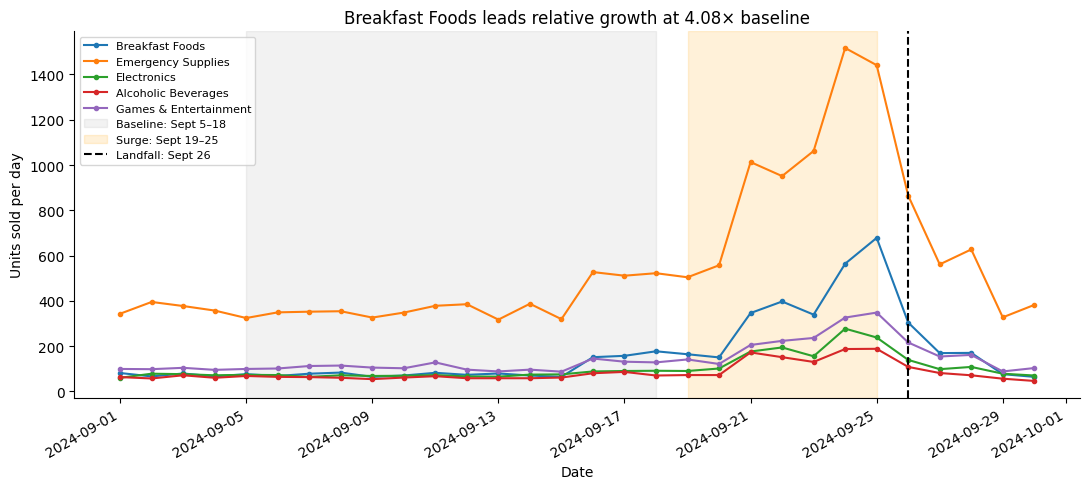

In [3]:
import matplotlib.pyplot as plt

top5 = q1_results.head(5).index

fig, ax = plt.subplots(figsize=(11, 5))

for category in top5:
    ax.plot(
        daily_units.index,
        daily_units[category],
        marker="o",
        markersize=3,
        label=category
    )

ax.axvspan(baseline_start, baseline_end,
           color="gray", alpha=0.1, label="Baseline: Sept 5–18")
ax.axvspan(surge_start, surge_end,
           color="orange", alpha=0.15, label="Surge: Sept 19–25")
ax.axvline(landfall, color="black", linestyle="--",
           label="Landfall: Sept 26")

ax.set_title(
    f"{top_category} leads relative growth at {q1_multiple:.2f}× baseline"
)
ax.set_xlabel("Date")
ax.set_ylabel("Units sold per day")
ax.legend(fontsize=8)
ax.spines[["top", "right"]].set_visible(False)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

Q1 — Demand surge identification

I compared September 19–25, the seven days before the assumed
September 26 landfall, with a September 5–18 baseline. Because
these windows contain seven and fourteen days respectively,
I compared average daily units rather than total sales.

The five categories with the greatest relative increases were:

| Category | Baseline units/day | Surge units/day | Increase |
|---|---:|---:|---:|
| Breakfast Foods | 92.29 | 376.86 | 308.36% |
| Emergency Supplies | 385.64 | 1,006.43 | 160.97% |
| Electronics | 74.14 | 175.86 | 137.19% |
| Alcoholic Beverages | 64.86 | 138.86 | 114.10% |
| Games & Entertainment | 109.43 | 228.57 | 108.88% |

Breakfast Foods had the largest relative surge at 4.08× baseline.
However, Emergency Supplies had the largest absolute increase
among these categories, approximately 621 additional units per day.
The daily trend chart shows purchasing accelerating near landfall.

The cleaning pipeline removed exact duplicates, parsed timestamps
and numeric quantities, and standardized category labels. It excluded
1,011 rows that lacked usable dates, categories, or nonnegative
quantities. These exclusions may affect the estimates if missing
records are concentrated in particular categories or periods.

Walmart should prioritize replenishment of Emergency Supplies
because of its large absolute demand increase, while increasing
Breakfast Foods availability to accommodate its strong relative
growth. These findings describe the supplied synthetic transactions;
they do not prove that the hurricane caused the increases.

### Q2 — SKU consolidation

Original catalog SKUs: 45
Canonical products after initial mapping: 43
Largest family by number of original SKUs: POPTART-STRAWBERRY-4PK
Original SKUs in this family: 3
Units before consolidation: 49584
Units after consolidation: 49584
PASS: consolidation preserved unit totals
Note: counts are packages sold; 4-packs and 6-packs stay separate.


,units_before
sku,
PT-12,1381
PT_STRAWBERRY,1262
SKU#459812,1255


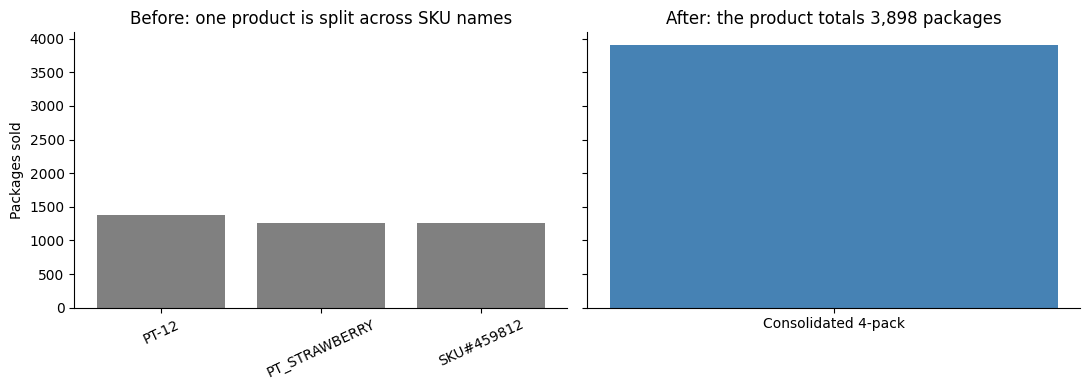

In [4]:
# Standardize SKU formatting.
catalog_clean = catalog.copy()
catalog_clean["sku"] = (
    catalog_clean["sku"].astype("string").str.strip().str.upper()
)

# Combine matching 4-pack variants; keep the 6-pack separate.
sku_mapping = {
    "PT-12": "POPTART-STRAWBERRY-4PK",
    "SKU#459812": "POPTART-STRAWBERRY-4PK",
    "PT_STRAWBERRY": "POPTART-STRAWBERRY-4PK",
    "POPTART-STRAW": "POPTART-STRAWBERRY-6PK"
}

catalog_clean["canonical_sku"] = (
    catalog_clean["sku"].replace(sku_mapping)
)

original_skus = catalog_clean["sku"].nunique()
canonical_products = catalog_clean["canonical_sku"].nunique()

# Compare the same valid quantities before and after mapping.
q2_sales = sales_clean.loc[
    sales_clean["quantity"].notna()
    & sales_clean["quantity"].ge(0)
].copy()

q2_sales["sku"] = (
    q2_sales["sku"].astype("string").str.strip().str.upper()
    .fillna("UNKNOWN")
)
q2_sales["canonical_sku"] = q2_sales["sku"].replace(sku_mapping)

before_total = q2_sales.groupby("sku")["quantity"].sum().sum()
after_total = q2_sales.groupby("canonical_sku")["quantity"].sum().sum()

assert before_total == after_total, "Unit totals changed!"

family_sizes = (
    catalog_clean.groupby("canonical_sku")["sku"]
    .nunique().sort_values(ascending=False)
)
largest_family = family_sizes.index[0]

family_sales = q2_sales[
    q2_sales["canonical_sku"].eq(largest_family)
]
fragmented = family_sales.groupby("sku")["quantity"].sum()
consolidated_total = fragmented.sum()

print("Original catalog SKUs:", original_skus)
print("Canonical products after initial mapping:", canonical_products)
print("Largest family by number of original SKUs:", largest_family)
print("Original SKUs in this family:", family_sizes.iloc[0])
print("Units before consolidation:", before_total)
print("Units after consolidation:", after_total)
print("PASS: consolidation preserved unit totals")
print("Note: counts are packages sold; 4-packs and 6-packs stay separate.")

display(fragmented.rename("units_before").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

axes[0].bar(fragmented.index, fragmented.values, color="gray")
axes[0].set_title("Before: one product is split across SKU names")
axes[0].set_ylabel("Packages sold")
axes[0].tick_params(axis="x", rotation=25)

axes[1].bar(["Consolidated 4-pack"], [consolidated_total],
            color="steelblue")
axes[1].set_title(
    f"After: the product totals {consolidated_total:,.0f} packages"
)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

Pop-Tarts rows excluded from daily analysis: 54


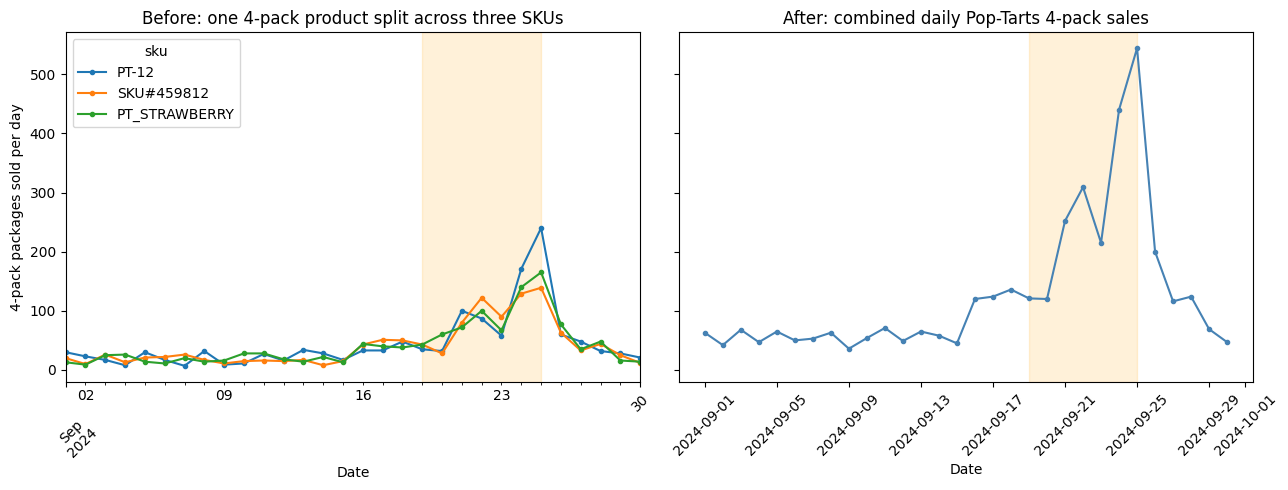

,value
September packages with valid dates,3766.00
September average packages/day,125.53
Baseline average packages/day,70.64
Surge average packages/day,285.86
Peak daily packages,544.00


Peak date: 2024-09-25


In [5]:
# Q2 — Daily fragmented versus consolidated Pop-Tarts sales
pop_skus = ["PT-12", "SKU#459812", "PT_STRAWBERRY"]

pop_sales = q2_sales.loc[q2_sales["sku"].isin(pop_skus)].copy()
missing_dates = pop_sales["timestamp"].isna().sum()
print("Pop-Tarts rows excluded from daily analysis:", missing_dates)

pop_sales = pop_sales.dropna(subset=["timestamp"])
pop_sales["date"] = pop_sales["timestamp"].dt.normalize()

pop_daily = (
    pop_sales.groupby(["date", "sku"])["quantity"]
    .sum()
    .unstack(fill_value=0)
    .reindex(
        index=pd.date_range("2024-09-01", "2024-09-30"),
        columns=pop_skus,
        fill_value=0
    )
)

pop_consolidated = pop_daily.sum(axis=1)

assert pop_consolidated.sum() == pop_daily.sum().sum()

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

pop_daily.plot(ax=axes[0], marker="o", markersize=3)
axes[0].set_title("Before: one 4-pack product split across three SKUs")

axes[1].plot(
    pop_consolidated.index, pop_consolidated,
    color="steelblue", marker="o", markersize=3
)
axes[1].set_title("After: combined daily Pop-Tarts 4-pack sales")

for ax in axes:
    ax.axvspan(surge_start, surge_end, color="orange", alpha=0.15)
    ax.set_xlabel("Date")
    ax.tick_params(axis="x", rotation=45)

axes[0].set_ylabel("4-pack packages sold per day")
plt.tight_layout()
plt.show()

pop_summary = pd.Series({
    "September packages with valid dates": pop_consolidated.sum(),
    "September average packages/day": pop_consolidated.mean(),
    "Baseline average packages/day":
        pop_consolidated.loc[baseline_start:baseline_end].mean(),
    "Surge average packages/day":
        pop_consolidated.loc[surge_start:surge_end].mean(),
    "Peak daily packages": pop_consolidated.max()
})

display(pop_summary.round(2).to_frame("value"))
print("Peak date:", pop_consolidated.idxmax().date())

FULL CATALOG AUDIT


,sku,product_name,product_family,package_size,package_normalized
0,PT-12,pop-tarts strawberry,Pop-Tarts Strawberry,4-pack,4-pack
1,SKU#459812,Strawberry Pop-Tart,Pop-Tarts Strawberry,4pk,4-pack
2,POPTART-STRAW,Pop-Tarts Strawberry,Pop-Tarts Strawberry,6 pack,6-pack
3,PT_STRAWBERRY,pop-tarts strawberry,Pop-Tarts Strawberry,4 pack,4-pack
4,WTR-24,BOTTLED WATER 24PK,Bottled Water,1 pack,1-pack
5,WATER24PK,Bottled Water 24-Pack,Bottled Water,24 pack,24-pack
6,WTR_24PK,Water - 24 Pack,Bottled Water,1 pack,1-pack
7,BATT-100,BATTERIES AA 4PK,AA Batteries,6 pack,6-pack
8,BAT-AA4,AA Batteries 4-Pack,AA Batteries,4pk,4-pack
9,BATT_AA_4PK,AA Batteries 4-Pack,AA Batteries,24 pack,24-pack


FAMILY REVIEW — different package labels require caution


,original_skus,package_labels,canonical_products
product_family,,,
AA Batteries,3,"24-pack, 4-pack, 6-pack",3
Bottled Water,3,"1-pack, 24-pack",3
Canned Soup,2,1-pack,1
Chips Variety Pack,2,"1-pack, 4-pack",2
Emergency Candles,2,"1-pack, 24-pack",2
First Aid Kit,2,4-pack,1
Heavy Duty Tarp,2,"12-pack, 24-pack",2
Infant Formula,2,"4-pack, 6-pack",2
LED Flashlight,2,"1-pack, 6-pack",2


Original catalog SKUs: 45
Canonical products after full review: 38
Sales quantities before: 49584
Sales quantities after: 49584
PASS: expanded consolidation preserved total quantities


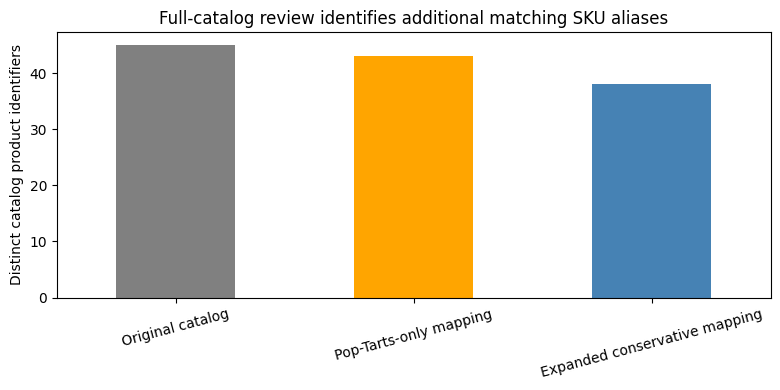

In [15]:
# Q2 — Audit the entire catalog for product aliases and package conflicts.
import re

# Product families are candidates for review, not proof of identical products.
families = {
    "Pop-Tarts Strawberry": [
        "PT-12", "SKU#459812", "POPTART-STRAW", "PT_STRAWBERRY"
    ],
    "Bottled Water": ["WTR-24", "WATER24PK", "WTR_24PK"],
    "AA Batteries": ["BATT-100", "BAT-AA4", "BATT_AA_4PK"],
    "LED Flashlight": ["FLASH-01", "LED-FLASH"],
    "Light Beer": ["BEER-24", "LTBEER24"],
    "Monopoly": ["BG-MONO", "MONOPOLY-01", "GAME-MONO"],
    "Playing Cards": ["CARDS-01", "PLAYCARD-STD"],
    "Streaming Device": ["STREAM-01", "ROKU-STD"],
    "Canned Soup": ["SOUP-CAN", "CNSOUP-01"],
    "White Bread": ["BREAD-WH", "WHITEBREAD"],
    "Peanut Butter": ["PB-16", "PNUTBTR-16"],
    "Emergency Candles": ["CNDL-EM", "CANDLE-EMRG"],
    "First Aid Kit": ["FAID-01", "FIRSTAID-KIT"],
    "Portable Charger": ["CHRG-PORT", "PORTCHARGER"],
    "Chips Variety Pack": ["CHIPS-VP", "CHIPVARIETY"],
    "Paper Towels": ["PTOWEL-6", "PAPERTOWEL6"],
    "Toilet Paper": ["TP-12", "TOILETPAPER12"],
    "Size 3 Diapers": ["DIAP-S3", "DIAPERS-3"],
    "Infant Formula": ["BFORM-01", "BABYFORMULA"],
    "Heavy Duty Tarp": ["TARP-HD", "HDTARP-01"]
}

family_lookup = {
    sku: family for family, skus in families.items() for sku in skus
}

def normalize_package(value):
    text = str(value).strip().lower()
    if text == "single":
        return "1-pack"
    match = re.fullmatch(r"(\d+)\s*[- ]?\s*(?:pack|pk)", text)
    if match:
        return f"{int(match.group(1))}-pack"
    return text  # Keep ambiguous labels such as "bundle" unchanged.

catalog_review = catalog.copy()
catalog_review["sku"] = (
    catalog_review["sku"].astype("string").str.strip().str.upper()
)
catalog_review["product_family"] = catalog_review["sku"].map(family_lookup)
catalog_review["package_normalized"] = (
    catalog_review["package_size"].map(normalize_package)
)

assert catalog_review["product_family"].notna().all(), "Unreviewed SKU"
assert catalog_review["sku"].is_unique, "Repeated catalog SKU needs review"

print("FULL CATALOG AUDIT")
display(catalog_review[
    ["sku", "product_name", "product_family",
     "package_size", "package_normalized"]
])

# Extend the existing Pop-Tarts mapping only where identity and
# package descriptions are sufficiently consistent.
# Uncertain families remain separate rather than being forced together.
extended_mapping = {
    **sku_mapping,
    "BEER-24": "LIGHT-BEER-24PK",
    "LTBEER24": "LIGHT-BEER-24PK",
    "SOUP-CAN": "CANNED-SOUP-SINGLE",
    "CNSOUP-01": "CANNED-SOUP-SINGLE",
    "BREAD-WH": "WHITE-BREAD-24PK",
    "WHITEBREAD": "WHITE-BREAD-24PK",
    "FAID-01": "FIRST-AID-KIT-4PK",
    "FIRSTAID-KIT": "FIRST-AID-KIT-4PK",
    "BG-MONO": "MONOPOLY-1PK",
    "GAME-MONO": "MONOPOLY-1PK"
}

catalog_review["canonical_sku"] = (
    catalog_review["sku"].replace(extended_mapping)
)

family_review = (
    catalog_review.groupby("product_family")
    .agg(
        original_skus=("sku", "nunique"),
        package_labels=("package_normalized",
                        lambda s: ", ".join(sorted(s.unique()))),
        canonical_products=("canonical_sku", "nunique")
    )
)

print("FAMILY REVIEW — different package labels require caution")
display(family_review)

# Verify the expanded mapping against the same valid-quantity sales.
expanded_sales = q2_sales.copy()
expanded_sales["canonical_sku_full"] = (
    expanded_sales["sku"].replace(extended_mapping)
)
expanded_total = (
    expanded_sales.groupby("canonical_sku_full")["quantity"].sum().sum()
)
assert expanded_total == before_total, "Mapping changed sales totals"

print("Original catalog SKUs:", catalog_review["sku"].nunique())
print("Canonical products after full review:",
      catalog_review["canonical_sku"].nunique())
print("Sales quantities before:", before_total)
print("Sales quantities after:", expanded_total)
print("PASS: expanded consolidation preserved total quantities")

counts = pd.Series({
    "Original catalog": catalog_review["sku"].nunique(),
    "Pop-Tarts-only mapping": canonical_products,
    "Expanded conservative mapping":
        catalog_review["canonical_sku"].nunique()
})
counts.plot.bar(figsize=(8, 4), color=["gray", "orange", "steelblue"])
plt.title("Full-catalog review identifies additional matching SKU aliases")
plt.ylabel("Distinct catalog product identifiers")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Q2 The Pop-Tarts effect

I consolidated PT-12, SKU#459812, and PT_STRAWBERRY into one strawberry Pop-Tarts 4-pack product, keeping the 6-pack separate. This initial mapping reduced the catalog from 45 SKUs to 43 canonical product identifiers. Consolidation preserved the overall recorded quantity total of 49,584 packages.

The combined 4-pack product recorded 3,898 packages across all valid-quantity rows. For daily analysis, 54 rows lacked usable timestamps and were excluded. The remaining September records contained 3,766 packages, averaging 125.53 per day. Missing-date sales were not assigned to guessed dates.

Average daily sales rose from 70.64 packages during September 5–18 to 285.86 during September 19–25, approximately 4.05× baseline. The peak was 544 packages on September 25.

I also reviewed all 45 catalog SKUs for additional product aliases and package-size differences. Extending the mapping to matching light beer, canned soup, white bread, first-aid kit, and Monopoly entries reduced the catalog to 38 canonical product identifiers. Total recorded sales quantities remained unchanged at 49,584. I kept uncertain matches and conflicting package sizes separate rather than assuming every product-family alias represented an identical package.

The fragmented view divides one product’s demand across multiple SKU labels, understating its total when any individual SKU is viewed alone. Consolidation reveals the combined replenishment requirement without creating additional sales. Walmart should plan inventory using consolidated demand for equivalent products while keeping different package sizes separate and verifying uncertain catalog entries.

Q3 — Weather correlation

Source: https://archive-api.open-meteo.com/v1/archive
Data: live API retrieval of historical weather; no fallback
Timezone: America/New_York
Daily rows before join: 30
Daily rows after join: 30
Days in correlation: 30


,precipitation_sum,wind_speed_10m_max
Alcoholic Beverages,-0.256,0.374
Baby Products,-0.361,0.234
Breakfast Foods,-0.242,0.407
Electronics,-0.245,0.357
Emergency Supplies,-0.258,0.406
Games & Entertainment,-0.201,0.452
Grocery,-0.288,0.320
Health & Wellness,-0.233,0.376
Household Essentials,-0.234,0.395
Snacks,-0.165,0.233


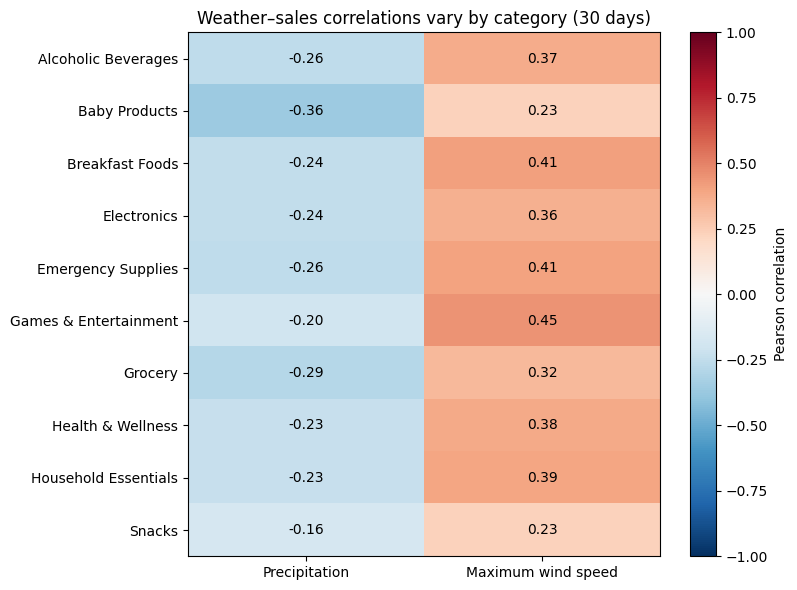

Caveat: one month and one weather location cannot establish causation or represent weather at every Florida store.


In [6]:
import requests
import matplotlib.pyplot as plt

# Historical Orlando weather, fetched directly from Open-Meteo.
url = "https://archive-api.open-meteo.com/v1/archive"
params = {
    "latitude": 28.54,
    "longitude": -81.38,
    "start_date": "2024-09-01",
    "end_date": "2024-09-30",
    "daily": "precipitation_sum,wind_speed_10m_max",
    "timezone": "America/New_York"
}

response = requests.get(url, params=params, timeout=60)
response.raise_for_status()

weather = pd.DataFrame(response.json()["daily"])
weather = weather.rename(columns={"time": "date"})
weather["date"] = pd.to_datetime(weather["date"])
assert weather["date"].is_unique

# Sales timestamps are assumed to be local Florida time.
sales_daily = daily_units.copy()
sales_daily.index.name = "date"
sales_daily = sales_daily.reset_index()

rows_before = len(sales_daily)
joined = sales_daily.merge(
    weather, on="date", how="left", validate="one_to_one"
)
rows_after = len(joined)

q3_join_rows_preserved = rows_before == rows_after
assert q3_join_rows_preserved
assert joined[
    ["precipitation_sum", "wind_speed_10m_max"]
].notna().all().all()

categories = daily_units.columns.tolist()
weather_columns = ["precipitation_sum", "wind_speed_10m_max"]

correlation_data = joined[
    categories + weather_columns
].dropna()
q3_days_in_correlation = len(correlation_data)

correlations = correlation_data.corr().loc[
    categories, weather_columns
]

print("Source:", url)
print("Data: live API retrieval of historical weather; no fallback")
print("Timezone: America/New_York")
print("Daily rows before join:", rows_before)
print("Daily rows after join:", rows_after)
print("Days in correlation:", q3_days_in_correlation)
display(correlations.round(3))

fig, ax = plt.subplots(figsize=(8, 6))
heatmap = ax.imshow(
    correlations.values, cmap="RdBu_r", vmin=-1, vmax=1,
    aspect="auto"
)

ax.set_xticks([0, 1])
ax.set_xticklabels(["Precipitation", "Maximum wind speed"])
ax.set_yticks(range(len(categories)))
ax.set_yticklabels(categories)

for row in range(len(categories)):
    for col in range(2):
        ax.text(
            col, row, f"{correlations.iloc[row, col]:.2f}",
            ha="center", va="center"
        )

ax.set_title(
    f"Weather–sales correlations vary by category ({q3_days_in_correlation} days)"
)
fig.colorbar(heatmap, ax=ax, label="Pearson correlation")
plt.tight_layout()
plt.show()

print(
    "Caveat: one month and one weather location cannot establish "
    "causation or represent weather at every Florida store."
)

Same-day weather correlations:


,precipitation_sum,wind_speed_10m_max,mean_pressure_hpa
Alcoholic Beverages,-0.256,0.374,-0.198
Baby Products,-0.361,0.234,-0.171
Breakfast Foods,-0.242,0.407,-0.277
Electronics,-0.245,0.357,-0.219
Emergency Supplies,-0.258,0.406,-0.277
Games & Entertainment,-0.201,0.452,-0.304
Grocery,-0.288,0.320,-0.182
Health & Wellness,-0.233,0.376,-0.270
Household Essentials,-0.234,0.395,-0.246
Snacks,-0.165,0.233,0.021


Strongest exploratory lag correlations:


,category,indicator,lag_days,r,n_days
35,Alcoholic Beverages,mean_pressure_hpa,-2,-0.617,28
11,Alcoholic Beverages,precipitation_sum,4,-0.338,26
20,Alcoholic Beverages,wind_speed_10m_max,-2,0.754,28
80,Baby Products,mean_pressure_hpa,-2,-0.669,28
52,Baby Products,precipitation_sum,0,-0.361,30
65,Baby Products,wind_speed_10m_max,-2,0.762,28
125,Breakfast Foods,mean_pressure_hpa,-2,-0.701,28
98,Breakfast Foods,precipitation_sum,1,-0.348,29
110,Breakfast Foods,wind_speed_10m_max,-2,0.815,28
170,Electronics,mean_pressure_hpa,-2,-0.685,28


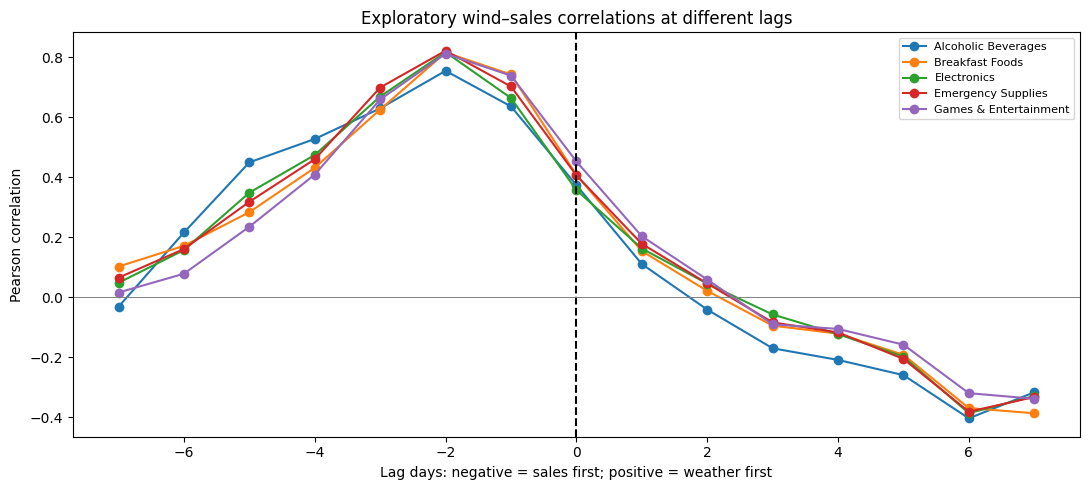

In [7]:
# Q3 — Add daily mean pressure from hourly API observations.
pressure_params = {
    "latitude": 28.54,
    "longitude": -81.38,
    "start_date": "2024-09-01",
    "end_date": "2024-09-30",
    "hourly": "pressure_msl",
    "timezone": "America/New_York"
}

pressure_response = requests.get(
    url, params=pressure_params, timeout=60
)
pressure_response.raise_for_status()

pressure_hourly = pd.DataFrame(
    pressure_response.json()["hourly"]
)
pressure_hourly["date"] = (
    pd.to_datetime(pressure_hourly["time"]).dt.normalize()
)
pressure_daily = (
    pressure_hourly.groupby("date")["pressure_msl"]
    .mean().rename("mean_pressure_hpa").reset_index()
)

weather_extended = joined.merge(
    pressure_daily, on="date", how="left",
    validate="one_to_one"
)
assert len(weather_extended) == len(joined)
assert weather_extended["mean_pressure_hpa"].notna().all()

weather_vars = [
    "precipitation_sum", "wind_speed_10m_max", "mean_pressure_hpa"
]
print("Same-day weather correlations:")
display(
    weather_extended[categories + weather_vars]
    .corr().loc[categories, weather_vars].round(3)
)

# Positive lag: weather occurs BEFORE sales.
# Negative lag: sales occur BEFORE weather.
lag_data = weather_extended.set_index("date").sort_index()
lag_rows = []

for category in categories:
    for indicator in weather_vars:
        for lag in range(-7, 8):
            pairs = pd.concat([
                lag_data[category].rename("sales"),
                lag_data[indicator].shift(lag).rename("weather")
            ], axis=1).dropna()

            lag_rows.append({
                "category": category,
                "indicator": indicator,
                "lag_days": lag,
                "r": pairs["sales"].corr(pairs["weather"]),
                "n_days": len(pairs)
            })

lag_results = pd.DataFrame(lag_rows)

# Display strongest absolute correlations as exploratory results.
best_indices = (
    lag_results.assign(abs_r=lag_results["r"].abs())
    .groupby(["category", "indicator"])["abs_r"].idxmax()
)
print("Strongest exploratory lag correlations:")
display(lag_results.loc[best_indices].round(3))

# Plot wind lags for the top five demand-surge categories.
wind_lags = (
    lag_results[
        lag_results["indicator"].eq("wind_speed_10m_max")
        & lag_results["category"].isin(top5)
    ]
    .pivot(index="lag_days", columns="category", values="r")
)

wind_lags.plot(figsize=(11, 5), marker="o")
plt.axvline(0, color="black", linestyle="--")
plt.axhline(0, color="gray", linewidth=0.7)
plt.title("Exploratory wind–sales correlations at different lags")
plt.xlabel("Lag days: negative = sales first; positive = weather first")
plt.ylabel("Pearson correlation")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

Q3 — Weather correlations and purchasing timing

I retrieved September 2024 Orlando weather from the Open-Meteo
Historical Weather API, including daily precipitation, maximum
wind speed, and hourly sea-level pressure aggregated to daily means.
The API used America/New_York time to align weather dates with
the assumed local sales timestamps. The validated join preserved
all 30 daily sales rows.

Same-day correlations alone missed the strongest timing relationship.
Across the five leading surge categories, wind correlations peaked
at a lag of −2 days, meaning sales preceded the corresponding wind
observations by two days. For example, Emergency Supplies had
r = 0.821 and Games & Entertainment had r = 0.811, each using
28 paired days.

Pressure showed a related pattern: Games & Entertainment sales
had r = −0.694 with pressure two days later. Higher sales therefore
aligned with lower subsequent pressure. Precipitation relationships
were weaker; the strongest absolute correlation for Games &
Entertainment was −0.366 at a positive four-day lag.

These patterns are consistent with purchasing in advance of severe
weather, but do not establish causation or a reliable forecasting
rule. The lag search examined multiple comparisons, daily observations
are not independent, and one month of Orlando weather does not
represent conditions at every Florida store. Additionally, the
transactions are synthetic while the weather observations are real.

Weather source: https://archive-api.open-meteo.com/v1/archive

## Q4 — Store-Level Geographic Patterns

,baseline_units_per_day,surge_units_per_day,surge_multiple,pre_landfall_peak_date,city,region,percent_increase
store_id,,,,,,,
FL-330,96.93,235.43,2.43,2024-09-24,Miami,South,142.89
FL-619,94.79,224.14,2.36,2024-09-24,Tallahassee,Panhandle,136.47
FL-105,98.71,231.71,2.35,2024-09-25,Tampa,West,134.73
FL-710,98.21,227.86,2.32,2024-09-25,Pensacola,Panhandle,132.00
FL-156,98.93,229.14,2.32,2024-09-24,Daytona Beach,East,131.62
FL-302,103.64,239.43,2.31,2024-09-25,Lakeland,Central,131.01
FL-412,98.29,222.86,2.27,2024-09-25,Jacksonville,North,126.74
FL-287,97.43,220.14,2.26,2024-09-25,Kissimmee,Central,125.95
FL-445,103.21,232.00,2.25,2024-09-24,St. Petersburg,West,124.78


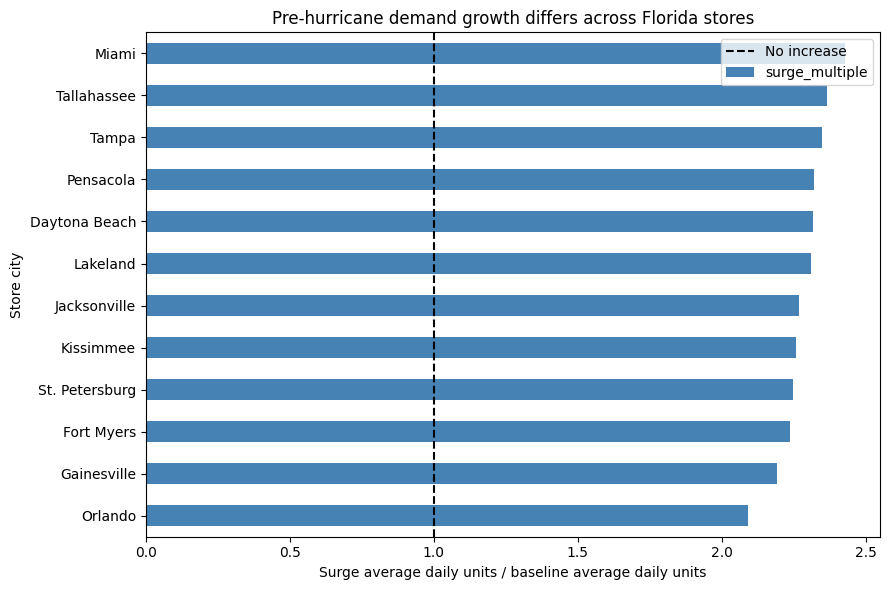

In [8]:
# Q4 — Compare hurricane demand across stores

def normalize_store_id(series):
    digits = (
        series.astype("string")
        .str.strip()
        .str.upper()
        .str.replace(r"[^0-9]", "", regex=True)
    )
    return "FL-" + digits.str.zfill(3)

stores_q4 = stores.copy()
stores_q4["store_id"] = normalize_store_id(stores_q4["store_id"])
stores_q4["region"] = stores_q4["region"].str.strip()
stores_q4 = stores_q4.drop_duplicates("store_id")

sales_q4 = analysis_sales.copy()
sales_q4["store_id"] = normalize_store_id(sales_q4["store_id"])

store_sales = sales_q4.merge(
    stores_q4[["store_id", "city", "region", "latitude", "longitude"]],
    on="store_id",
    how="left",
    validate="many_to_one"
)

assert len(store_sales) == len(sales_q4)
assert store_sales["city"].notna().all(), "Some stores did not match"

store_daily = (
    store_sales.groupby(["date", "store_id"])["quantity"]
    .sum()
    .unstack(fill_value=0)
    .reindex(daily_units.index, fill_value=0)
)

store_baseline = store_daily.loc[baseline_start:baseline_end].mean()
store_surge = store_daily.loc[surge_start:surge_end].mean()

q4_results = pd.DataFrame({
    "baseline_units_per_day": store_baseline,
    "surge_units_per_day": store_surge,
    "surge_multiple": store_surge / store_baseline.replace(0, float("nan")),
    "pre_landfall_peak_date": (
        store_daily.loc[baseline_start:surge_end].idxmax()
    )
}).join(stores_q4.set_index("store_id")[["city", "region"]])

q4_results["percent_increase"] = (
    q4_results["surge_multiple"] - 1
) * 100

q4_results = q4_results.sort_values("surge_multiple", ascending=False)
display(q4_results.round(2))

plot_data = q4_results.set_index("city").sort_values("surge_multiple")

ax = plot_data["surge_multiple"].plot.barh(
    figsize=(9, 6), color="steelblue"
)
ax.axvline(1, color="black", linestyle="--", label="No increase")
ax.set_xlabel("Surge average daily units / baseline average daily units")
ax.set_ylabel("Store city")
ax.set_title("Pre-hurricane demand growth differs across Florida stores")
ax.legend()
plt.tight_layout()
plt.show()

,city,region,surge_multiple,surge_onset,pre_landfall_peak_date,outlier
store_id,,,,,,
FL-330,Miami,South,2.43,2024-09-21,2024-09-24,False
FL-619,Tallahassee,Panhandle,2.36,2024-09-20,2024-09-24,False
FL-105,Tampa,West,2.35,2024-09-21,2024-09-25,False
FL-710,Pensacola,Panhandle,2.32,2024-09-21,2024-09-25,False
FL-156,Daytona Beach,East,2.32,2024-09-21,2024-09-24,False
FL-302,Lakeland,Central,2.31,2024-09-21,2024-09-25,False
FL-412,Jacksonville,North,2.27,2024-09-21,2024-09-25,False
FL-287,Kissimmee,Central,2.26,2024-09-21,2024-09-25,False
FL-445,St. Petersburg,West,2.25,2024-09-21,2024-09-24,False


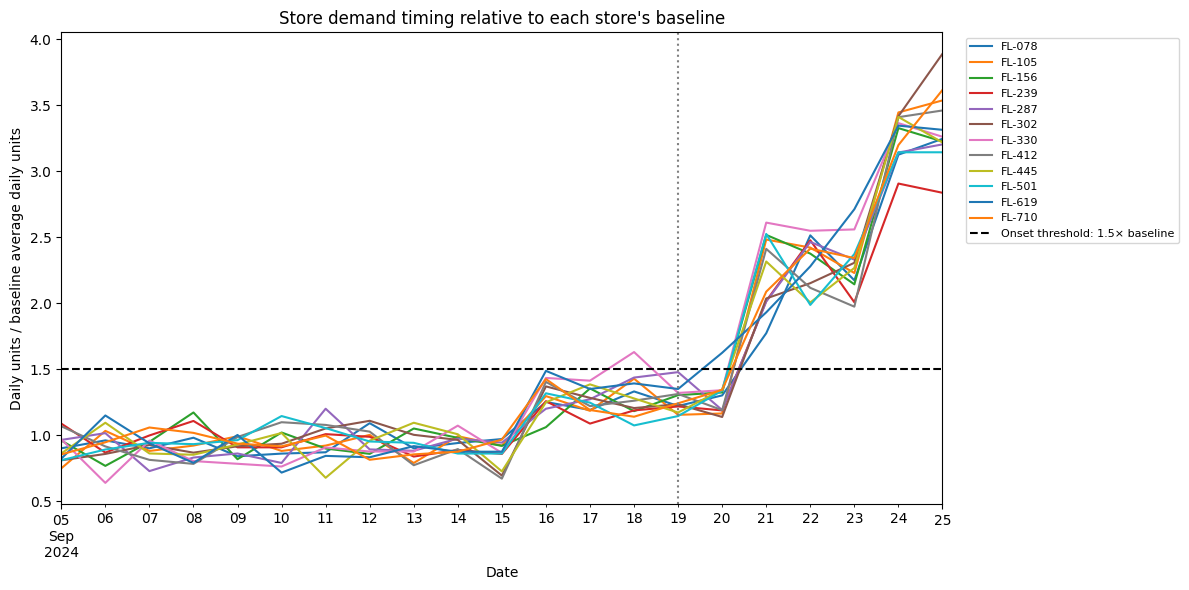

In [9]:
# Identify unusually large/small surges using the IQR rule.
multiples = q4_results["surge_multiple"]
q25, q75 = multiples.quantile([0.25, 0.75])
iqr = q75 - q25

q4_results["outlier"] = (
    (multiples < q25 - 1.5 * iqr)
    | (multiples > q75 + 1.5 * iqr)
)

# Define onset as the first of two consecutive days above
# 1.5 times that store's baseline daily sales.
relative_daily = store_daily.div(store_baseline, axis="columns")
pre_storm = relative_daily.loc[surge_start:surge_end]
sustained = pre_storm.gt(1.5) & pre_storm.shift(-1).gt(1.5)

onset = sustained.apply(
    lambda col: col.index[col][0] if col.any() else pd.NaT
)
q4_results["surge_onset"] = onset

display(q4_results[
    ["city", "region", "surge_multiple",
     "surge_onset", "pre_landfall_peak_date", "outlier"]
].round(2))

ax = relative_daily.loc[baseline_start:surge_end].plot(
    figsize=(12, 6)
)
ax.axhline(1.5, color="black", linestyle="--",
           label="Onset threshold: 1.5× baseline")
ax.axvline(surge_start, color="gray", linestyle=":")
ax.set_title("Store demand timing relative to each store's baseline")
ax.set_xlabel("Date")
ax.set_ylabel("Daily units / baseline average daily units")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

Excluded for missing coordinates: ['Tallahassee']


,city,forecast_distance_km,surge_multiple,onset_days_before_landfall
store_id,,,,
FL-078,Gainesville,193.69,2.19,5
FL-445,St. Petersburg,211.08,2.25,5
FL-105,Tampa,223.46,2.35,5
FL-412,Jacksonville,252.81,2.27,5
FL-302,Lakeland,269.28,2.31,5
FL-710,Pensacola,292.09,2.32,5
FL-239,Orlando,309.82,2.09,5
FL-287,Kissimmee,313.90,2.26,5
FL-501,Fort Myers,315.17,2.24,5


Distance–surge correlation: 0.465
Source: https://ftp.nhc.noaa.gov/atcf/archive/2024/messages/al092024.discus.005


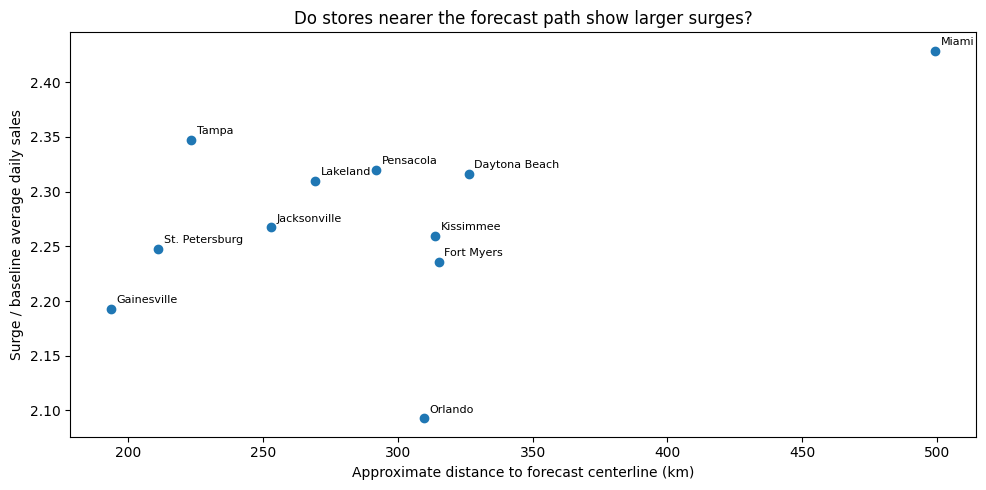

In [10]:
# Q4 — Compare store demand with proximity to a documented forecast.
import numpy as np

forecast_source = (
    "https://ftp.nhc.noaa.gov/atcf/archive/2024/messages/"
    "al092024.discus.005"
)

# NHC forecast issued September 24, 2024, at 11 a.m. EDT.
# Coordinates transcribed from its forecast-position table.
track = np.array([
    [19.5, -84.3],
    [20.3, -85.2],
    [21.5, -86.3],
    [23.2, -86.3],
    [25.9, -85.4],
    [29.7, -84.3],
    [33.9, -83.9]
])

# Approximate distance to the forecast centerline using a local
# planar projection and the nearest point on each track segment.
def project_km(lat, lon):
    return np.array([
        6371 * np.radians(lon) * np.cos(np.radians(28)),
        6371 * np.radians(lat)
    ])

track_xy = np.array([project_km(lat, lon) for lat, lon in track])

def distance_to_track(lat, lon):
    point = project_km(lat, lon)
    distances = []
    for start, end in zip(track_xy[:-1], track_xy[1:]):
        segment = end - start
        fraction = np.clip(
            np.dot(point - start, segment) / np.dot(segment, segment),
            0, 1
        )
        closest = start + fraction * segment
        distances.append(np.linalg.norm(point - closest))
    return min(distances)

geo_results = q4_results.join(
    stores_q4.set_index("store_id")[["latitude", "longitude"]]
)

for column in ["latitude", "longitude"]:
    geo_results[column] = pd.to_numeric(
        geo_results[column], errors="coerce"
    )

print("Excluded for missing coordinates:",
      geo_results.loc[
          geo_results[["latitude", "longitude"]].isna().any(axis=1),
          "city"
      ].tolist())

geo_results = geo_results.dropna(subset=["latitude", "longitude"]).copy()
geo_results["forecast_distance_km"] = geo_results.apply(
    lambda row: distance_to_track(row["latitude"], row["longitude"]),
    axis=1
)
geo_results["onset_days_before_landfall"] = (
    landfall - geo_results["surge_onset"]
).dt.days

display(
    geo_results[
        ["city", "forecast_distance_km", "surge_multiple",
         "onset_days_before_landfall"]
    ].sort_values("forecast_distance_km").round(2)
)

print("Distance–surge correlation:",
      round(geo_results["forecast_distance_km"].corr(
          geo_results["surge_multiple"]), 3))
print("Source:", forecast_source)

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(
    geo_results["forecast_distance_km"],
    geo_results["surge_multiple"]
)
for _, row in geo_results.iterrows():
    ax.annotate(
        row["city"],
        (row["forecast_distance_km"], row["surge_multiple"]),
        xytext=(4, 4), textcoords="offset points", fontsize=8
    )

ax.set_xlabel("Approximate distance to forecast centerline (km)")
ax.set_ylabel("Surge / baseline average daily sales")
ax.set_title("Do stores nearer the forecast path show larger surges?")
plt.tight_layout()
plt.show()

Q4 — Store-level geographic patterns

I standardized store IDs and removed duplicate store-location
records before joining transactions to store metadata. The join
preserved transaction rows and matched every analyzed transaction
to a city.

All 12 stores experienced increased average daily sales during
September 19–25 compared with September 5–18. Miami had the
largest relative surge at 2.43× baseline (+142.89%), followed by
Tallahassee at 2.36× (+136.47%) and Tampa at 2.35× (+134.73%).
Orlando had the smallest increase at 2.09× (+109.27%).

Using the 1.5×IQR rule on store surge multiples, Orlando was
flagged as a low-side outlier. This identifies an unusually small
relative increase within this dataset, not necessarily a data error.

I defined surge onset as the first of two consecutive days above
1.5× each store's baseline average. Within the September 19–25
search window, Tallahassee's onset was September 20; all other
stores crossed the threshold on September 21. Every store reached
its pre-landfall peak on September 24 or 25.

Using Helene’s September 24, 2024 NHC forecast as an external
geographic reference, I calculated approximate distances from
11 stores to the forecast centerline. Tallahassee was excluded
because its coordinates were missing.

The results did not support larger surges at closer stores.
Distance and surge magnitude had a positive correlation of 0.465:
farther stores tended to have larger increases in this small sample.
Miami was farthest from the centerline, approximately 499 km,
yet had the largest surge. All 11 mapped stores had the same
measured onset date, September 21, providing no evidence of
earlier purchasing at closer stores.

This is an exploratory comparison of synthetic sales with a real
forecast, not proof of hurricane effects. The forecast was issued
after the measured onset, distances are approximate, and distance
to the centerline does not capture the full area of storm impacts.

Forecast source:
https://ftp.nhc.noaa.gov/atcf/archive/2024/messages/al092024.discus.005

Recommendation: use store-specific baseline demand and current
inventory when allocating supplies. Avoid assuming that region
alone explains demand differences.

## Q5 — Signal vs. Artifact: The Board Games Investigation

In [11]:
import sqlite3
from pathlib import Path

db_path = Path("inventory_and_sales.db")
db_response = requests.get(
    BASE + "inventory_and_sales.db", timeout=60
)
db_response.raise_for_status()
db_path.write_bytes(db_response.content)

with sqlite3.connect(db_path) as conn:
    for table in ["daily_sales_summary", "inventory_levels"]:
        print(f"\n--- {table}: columns ---")
        display(pd.read_sql_query(f"PRAGMA table_info({table})", conn))

        print("Sample rows:")
        display(pd.read_sql_query(f"SELECT * FROM {table} LIMIT 5", conn))


--- daily_sales_summary: columns ---


,cid,name,type,notnull,dflt_value,pk
0,0,date,TEXT,0,None,0
1,1,store_id,TEXT,0,None,0
2,2,category,TEXT,0,None,0
3,3,total_units,REAL,0,None,0
4,4,total_revenue,REAL,0,None,0


Sample rows:


,date,store_id,category,total_units,total_revenue
0,2024-09-12,FL-239,Emergency,90.0,1582.55
1,2024-09-12,FL-239,Breakfast,57.0,356.99
2,2024-09-12,FL-239,Alcohol,41.0,246.65
3,2024-09-12,FL-239,Entertainment,53.0,916.56
4,2024-09-12,FL-239,Grocery,69.0,339.30



--- inventory_levels: columns ---


,cid,name,type,notnull,dflt_value,pk
0,0,date,TEXT,0,None,0
1,1,store_id,TEXT,0,None,0
2,2,sku,TEXT,0,None,0
3,3,units_on_hand,INTEGER,0,None,0
4,4,units_on_order,INTEGER,0,None,0
5,5,reorder_point,INTEGER,0,None,0


Sample rows:


,date,store_id,sku,units_on_hand,units_on_order,reorder_point
0,2024-09-12,FL-239,CHIPS-VP,112,5,31
1,2024-09-12,FL-239,PAPERTOWEL6,106,46,36
2,2024-09-12,FL-239,PT-12,62,36,30
3,2024-09-12,FL-239,PORTCHARGER,185,62,40
4,2024-09-12,FL-239,BFORM-01,88,1,35


Database coverage: 2024-09-01 00:00:00 through 2024-09-30 00:00:00
Duplicate date/store/category rows: 113

Entertainment products in transactions:


units
sku          product_name                 
PLAYCARD-STD Playing Cards             412
             Standard Playing Cards    412
CARDS-01     Playing Cards             391
             Standard Playing Cards    384
PLAYCARD-STD PLAYING CARDS             367
CARDS-01     PLAYING CARDS             346
GAME-MONO    Board Game - Monopoly     253
BG-MONO      Monopoly Board Game       248
MONOPOLY-01  Board Game - Monopoly     226
GAME-MONO    MONOPOLY                  214
             Monopoly Board Game       205
MONOPOLY-01  MONOPOLY                  204
             Monopoly Board Game       203
BG-MONO      Board Game - Monopoly     196
             MONOPOLY                  189


Product catalog columns:
['sku', 'product_name', 'category', 'subcategory', 'unit_cost', 'supplier', 'package_size']


,sku,product_name,category,subcategory,unit_cost,supplier,package_size
0,PT-12,pop-tarts strawberry,Breakfast Foods,NaN,1.93,Johnson & Johnson,4-pack
1,SKU#459812,Strawberry Pop-Tart,Breakfast,Pop-Tarts,2.26,Roku Inc,4pk
2,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,NaN,2.11,Sara Lee,6 pack
3,PT_STRAWBERRY,pop-tarts strawberry,breakfast,Pop-Tarts,NaN,Campbell's,4 pack
4,WTR-24,BOTTLED WATER 24PK,Emergency Supplies,Bottled,2.64,Sara Lee,1 pack



Source coverage:
Matched date/store pairs: 338
CSV-only pairs: 22
Database-only pairs: 0

Largest differences on matched date/store pairs:


csv_units  db_units  difference
date       store_id                                 
2024-09-24 FL-619           25     303.0       278.0
2024-09-25 FL-330           19     267.0       248.0
2024-09-24 FL-302           30     262.0       232.0
2024-09-25 FL-501           30     257.0       227.0
2024-09-24 FL-710           32     256.0       224.0
           FL-105           29     244.0       215.0
           FL-445           29     229.0       200.0
           FL-156           15     210.0       195.0
2024-09-25 FL-287           19     212.0       193.0
2024-09-23 FL-287           19     208.0       189.0

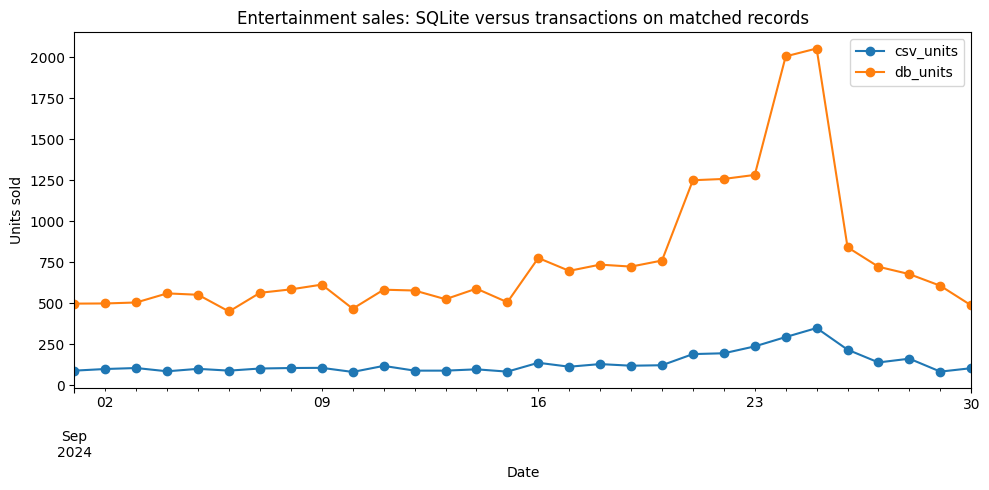

In [12]:
# Q5 — Audit entertainment sales in SQLite versus transactions
with sqlite3.connect(db_path) as conn:
    db_sales = pd.read_sql_query(
        "SELECT * FROM daily_sales_summary", conn
    )
    inventory = pd.read_sql_query(
        "SELECT * FROM inventory_levels", conn
    )

db_sales["date"] = pd.to_datetime(db_sales["date"], errors="coerce")
db_sales["store_id"] = normalize_store_id(db_sales["store_id"])
db_sales["category_clean"] = (
    db_sales["category"].astype("string")
    .str.strip().str.lower().map(category_map)
)
db_sales["total_units"] = pd.to_numeric(
    db_sales["total_units"], errors="coerce"
)

print("Database coverage:", db_sales["date"].min(),
      "through", db_sales["date"].max())
print("Duplicate date/store/category rows:",
      db_sales.duplicated(["date", "store_id", "category_clean"]).sum())

# Audit products classified as entertainment in the transactions.
games = analysis_sales.loc[
    analysis_sales["category_clean"].eq("Games & Entertainment")
].copy()
games["sku"] = games["sku"].astype("string").str.strip().str.upper()

print("\nEntertainment products in transactions:")
display(
    games.groupby(["sku", "product_name"], dropna=False)["quantity"]
    .sum().sort_values(ascending=False).rename("units").to_frame()
)

print("\nProduct catalog columns:")
print(catalog.columns.tolist())
display(catalog.head())

# Compare both sources over the same dates and stores.
csv_daily = (
    games.assign(store_id=normalize_store_id(games["store_id"]))
    .groupby(["date", "store_id"])["quantity"].sum()
    .rename("csv_units")
)
db_daily = (
    db_sales.loc[
        db_sales["category_clean"].eq("Games & Entertainment")
    ]
    .groupby(["date", "store_id"])["total_units"].sum()
    .rename("db_units")
)

comparison = pd.concat([csv_daily, db_daily], axis=1)
matched = comparison.dropna().copy()

print("\nSource coverage:")
print("Matched date/store pairs:", len(matched))
print("CSV-only pairs:", comparison["db_units"].isna().sum())
print("Database-only pairs:", comparison["csv_units"].isna().sum())

matched["difference"] = matched["db_units"] - matched["csv_units"]
print("\nLargest differences on matched date/store pairs:")
display(
    matched.loc[
        matched["difference"].abs().sort_values(ascending=False).index
    ].head(10)
)

matched.groupby(level="date")[["csv_units", "db_units"]].sum().plot(
    figsize=(10, 5), marker="o"
)
plt.title("Entertainment sales: SQLite versus transactions on matched records")
plt.ylabel("Units sold")
plt.xlabel("Date")
plt.tight_layout()
plt.show()

In [13]:
# Show entertainment products without truncating the output.
product_audit = (
    games.groupby(["sku", "product_name"], dropna=False)["quantity"]
    .sum()
    .sort_values(ascending=False)
    .rename("units")
    .reset_index()
)

print("ENTERTAINMENT PRODUCTS IN TRANSACTIONS")
print(product_audit.to_string(index=False))

# Inspect catalog entries matching those SKUs.
catalog_audit = catalog.copy()
catalog_audit["sku"] = (
    catalog_audit["sku"].astype("string").str.strip().str.upper()
)
game_skus = games["sku"].dropna().unique()

print("\nMATCHING CATALOG ENTRIES")
print(
    catalog_audit.loc[catalog_audit["sku"].isin(game_skus)]
    .to_string(index=False)
)

# Inspect inventory coverage for these products.
inventory["sku"] = (
    inventory["sku"].astype("string").str.strip().str.upper()
)
inventory["date"] = pd.to_datetime(inventory["date"], errors="coerce")
inventory["store_id"] = normalize_store_id(inventory["store_id"])

game_inventory = inventory.loc[
    inventory["sku"].isin(game_skus)
].copy()

print("\nENTERTAINMENT INVENTORY")
print("Rows:", len(game_inventory))
print("Date range:", game_inventory["date"].min(),
      "through", game_inventory["date"].max())
print(
    game_inventory.sort_values(["sku", "store_id", "date"])
    .head(20).to_string(index=False)
)

ENTERTAINMENT PRODUCTS IN TRANSACTIONS
         sku           product_name  units
PLAYCARD-STD          Playing Cards    412
PLAYCARD-STD Standard Playing Cards    412
    CARDS-01          Playing Cards    391
    CARDS-01 Standard Playing Cards    384
PLAYCARD-STD          PLAYING CARDS    367
    CARDS-01          PLAYING CARDS    346
   GAME-MONO  Board Game - Monopoly    253
     BG-MONO    Monopoly Board Game    248
 MONOPOLY-01  Board Game - Monopoly    226
   GAME-MONO               MONOPOLY    214
   GAME-MONO    Monopoly Board Game    205
 MONOPOLY-01               MONOPOLY    204
 MONOPOLY-01    Monopoly Board Game    203
     BG-MONO  Board Game - Monopoly    196
     BG-MONO               MONOPOLY    189

MATCHING CATALOG ENTRIES
         sku          product_name      category subcategory  unit_cost        supplier package_size
     BG-MONO   Monopoly Board Game ENTERTAINMENT         NaN       9.96  Kimberly-Clark          1pk
 MONOPOLY-01   Monopoly Board Game entertainm

PRODUCT GROUP GROWTH — TRANSACTION PACKAGE COUNTS


,baseline_units_per_day,surge_units_per_day,multiple,percent_increase
product_group,,,,
Board games,46.07,111.43,2.42,141.86
Playing cards,63.36,117.14,1.85,84.89


ENTERTAINMENT GROWTH — MATCHED RECORDS ONLY


,baseline_units_per_day,surge_units_per_day,multiple,percent_increase
csv_units,101.71,214.14,2.11,110.53
db_units,586.46,1333.36,2.27,127.36


BOARD-GAME INVENTORY QUALITY
Snapshot rows: 277
Missing on-order values: 45
Duplicate date/store/SKU snapshots: 0
Snapshots below reorder point: 54 of 277


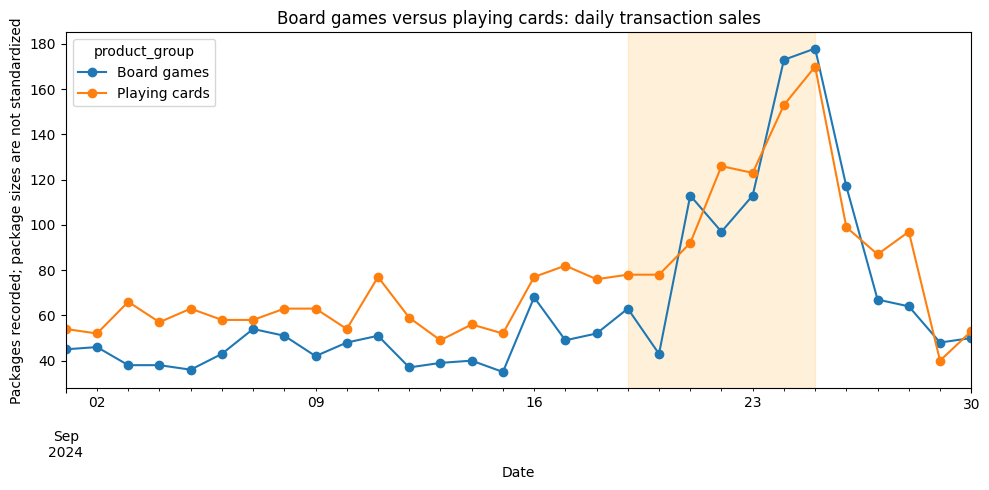

In [14]:
# Q5 — Separate board games from cards without changing package units.
board_skus = ["BG-MONO", "MONOPOLY-01", "GAME-MONO"]
card_skus = ["CARDS-01", "PLAYCARD-STD"]

games["product_group"] = games["sku"].map({
    **dict.fromkeys(board_skus, "Board games"),
    **dict.fromkeys(card_skus, "Playing cards")
})

assert games["product_group"].notna().all(), "Unclassified game SKU"

product_daily = (
    games.groupby(["date", "product_group"])["quantity"]
    .sum().unstack(fill_value=0)
    .reindex(daily_units.index, fill_value=0)
)

product_growth = pd.DataFrame({
    "baseline_units_per_day":
        product_daily.loc[baseline_start:baseline_end].mean(),
    "surge_units_per_day":
        product_daily.loc[surge_start:surge_end].mean()
})
product_growth["multiple"] = (
    product_growth["surge_units_per_day"]
    / product_growth["baseline_units_per_day"]
)
product_growth["percent_increase"] = (
    product_growth["multiple"] - 1
) * 100

print("PRODUCT GROUP GROWTH — TRANSACTION PACKAGE COUNTS")
display(product_growth.round(2))

# Compare sources using identical matched date/store pairs.
matched_daily = (
    matched.groupby(level="date")[["csv_units", "db_units"]].sum()
)

source_growth = pd.DataFrame({
    "baseline_units_per_day":
        matched_daily.loc[baseline_start:baseline_end].mean(),
    "surge_units_per_day":
        matched_daily.loc[surge_start:surge_end].mean()
})
source_growth["multiple"] = (
    source_growth["surge_units_per_day"]
    / source_growth["baseline_units_per_day"]
)
source_growth["percent_increase"] = (
    source_growth["multiple"] - 1
) * 100

print("ENTERTAINMENT GROWTH — MATCHED RECORDS ONLY")
display(source_growth.round(2))

# Inventory observations are sparse snapshots, not daily sales.
board_inventory = game_inventory.loc[
    game_inventory["sku"].isin(board_skus)
].copy()

for col in ["units_on_hand", "units_on_order", "reorder_point"]:
    board_inventory[col] = pd.to_numeric(
        board_inventory[col], errors="coerce"
    )

print("BOARD-GAME INVENTORY QUALITY")
print("Snapshot rows:", len(board_inventory))
print("Missing on-order values:",
      board_inventory["units_on_order"].isna().sum())
print("Duplicate date/store/SKU snapshots:",
      board_inventory.duplicated(["date", "store_id", "sku"]).sum())

observed = board_inventory.dropna(
    subset=["units_on_hand", "reorder_point"]
)
print("Snapshots below reorder point:",
      (observed["units_on_hand"] < observed["reorder_point"]).sum(),
      "of", len(observed))

product_daily.plot(figsize=(10, 5), marker="o")
plt.axvspan(surge_start, surge_end, color="orange", alpha=0.15)
plt.title("Board games versus playing cards: daily transaction sales")
plt.xlabel("Date")
plt.ylabel("Packages recorded; package sizes are not standardized")
plt.tight_layout()
plt.show()

 Q5 Signal versus artifact: board games

Using September 5–18 as the baseline and September 19–25 as the
surge period, recorded board-game sales increased from 46.07 to
111.43 packages per day: 2.42× baseline, or +141.86%. Playing cards
increased by 84.89%. Therefore, the broader entertainment category
should not be treated as board-game sales alone.

The SQLite summary and transaction CSV disagree substantially.
On matched date/store records, entertainment sales increased by
127.36% in SQLite versus 110.53% in the CSV. Neither comparison
reproduces the stated +250% increase under our chosen windows.
This discrepancy warrants investigation; it does not establish
which source is correct or prove a specific reporting error.

The catalog also contains inconsistent package sizes across
Monopoly SKUs, so these results represent recorded package counts,
not standardized individual games. Inventory provides 277 board-game
snapshots, including 45 missing on-order values and 54 observations
below the reorder point. Sparse snapshots cannot establish inventory
reporting lag or prove that stockouts caused lost sales.

Recommendation: make a cautious, targeted increase in board-game
stock rather than ordering based on the unverified +250% claim.
Prioritize stores with confirmed low inventory, verify incoming
orders and package sizes, and reconcile the sales sources before
setting a larger replenishment target.

## Reflection
1. Data Quality Impact

Pop-Tarts sales data were available in three SKUs of the same product (4-pack). Consolidating the three SKUs revealed 3,898 Pop-Tarts packages sold, while the overall total across all products remained unchanged at 49,584 packages. Without consolidation, we would have underestimated the popularity of the product and could have faced shortages. In terms of the daily analysis, I decided to exclude 54 Pop-Tarts rows with no date information from the analysis rather than trying to guess their dates, thus leaving 3,766 packages with valid dates.

2. ETL Trade-offs

I decided to exclude all transactions with unusable timestamp information from the daily comparison. It is possible to impute the date information; however, it will preserve more sales, but misplace some of them into baseline/surge periods. For Pop-Tarts, I had 132 packages to exclude from the daily analysis due to no date information. I would make the same decision since purchase time is critical for this project.

3. Pipeline Trust

An unreliable pipeline is indeed riskier than a model. Calculating the comparison of total sales in fourteen days to seven days will give less increase because the Breakfast Foods ratio will be approximately 2.04 instead of 4.08 times. The least reliable aspects of the pipeline are the date calculation, the SKU matching, and the join. Preserved-total assertions and validated joins helped to ensure that transformations were preserving the sales without creating or losing them, even though they do not necessarily guarantee the correctness of the initial records.

4. Business vs. Data

In the board games investigation, it was necessary to balance the risk of shortages and overstocking. The transaction data indicated that there was a 141.86% increase in average daily package sales of board games; however, the SQLite summary had different figures compared to the transactions, the package sizes varied, and there was no complete inventory history. I therefore recommended cautiously increasing board-game stock only at stores with verified inventory needs. Given additional time, I would reconcile the sales from both sources, define the packages, and get inventory/delivery history.

5. Team Collaboration

The project was completed entirely on my own effort, with responsibilities including data cleaning, SKU consolidation, API calls for weather information, queries in SQLite database, and analysis of results. Doing this all by myself helped me keep everything uniform, but at the same time did not allow for an external check of my assumptions. If I were to have another week, my priorities would include getting an external evaluation, better automated checks, and reconciliation of results from SQLite and transactions. The most useful skill I acquired is the ability to trace results back in the pipeline.

## Final Recommendation

Walmart should focus on Emergency Supplies and Breakfast Foods prior to the next storm. Emergency Supplies recorded the highest increase in absolute terms, whereas Breakfast Foods recorded the highest increase in relative terms (4.08× baseline). Pop-Tarts replenishments should be done on the basis of consolidated SKU demand without mixing different sizes.

Determine stocks by taking into account the sales baseline and the needs of each store. The geographic analysis does not justify assuming that stores near the forecast centerline will experience earlier or larger surges. Board games should be increased cautiously since our analysis did not reproduce the claimed +250% increase. Verify totals for SQLite and transactions, package sizes, and the incoming inventory.

Based on the weather analysis, purchasing occurred about two days ahead of strong winds; however, the relationship is exploratory and not a forecast.